In [1]:
!pip install -q shap

In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
import shap
import requests

from tensorflow.keras import layers
from keras.preprocessing.image import load_img, img_to_array
from sklearn.metrics import confusion_matrix, classification_report

import requests
import zipfile

In [3]:
# Criar a pasta para armazenar o dataset
folder = "/content/RAF-DB"
os.makedirs(folder, exist_ok=True)

# URL do dataset no Kaggle
url = "https://www.kaggle.com/api/v1/datasets/download/dollyprajapati182/balanced-raf-db-dataset-7575-grayscale"


# Baixar o arquivo ZIP
response = requests.get(url, stream=True)
response.raise_for_status()

zip_file = f"{folder}/balanced-raf-db-dataset-7575-grayscale.zip"

with open(zip_file, "wb") as file_:
    for block in response.iter_content(chunk_size=1024 * 1024):
        if block:
            file_.write(block)

print("Download concluído!")

Download concluído!


In [4]:
  # Descompactar arquivo ZIP
with zipfile.ZipFile("/content/RAF-DB/balanced-raf-db-dataset-7575-grayscale.zip", "r") as file_:
    file_.extractall("/content/RAF-DB")

print("Dataset extraído com sucesso!")

for root, folders, felis in os.walk("/content/RAF-DB"):
    level = root.replace("/content/RAF-DB", "").count(os.sep)
    print("  " * level + os.path.basename(root) + "/")

Dataset extraído com sucesso!
RAF-DB/
  train/
    happy/
    angry/
    neutral/
    fear/
    surprise/
    sad/
    disgust/
  val/
    happy/
    angry/
    neutral/
    fear/
    surprise/
    sad/
    disgust/
  test/
    happy/
    angry/
    neutral/
    fear/
    surprise/
    sad/
    disgust/


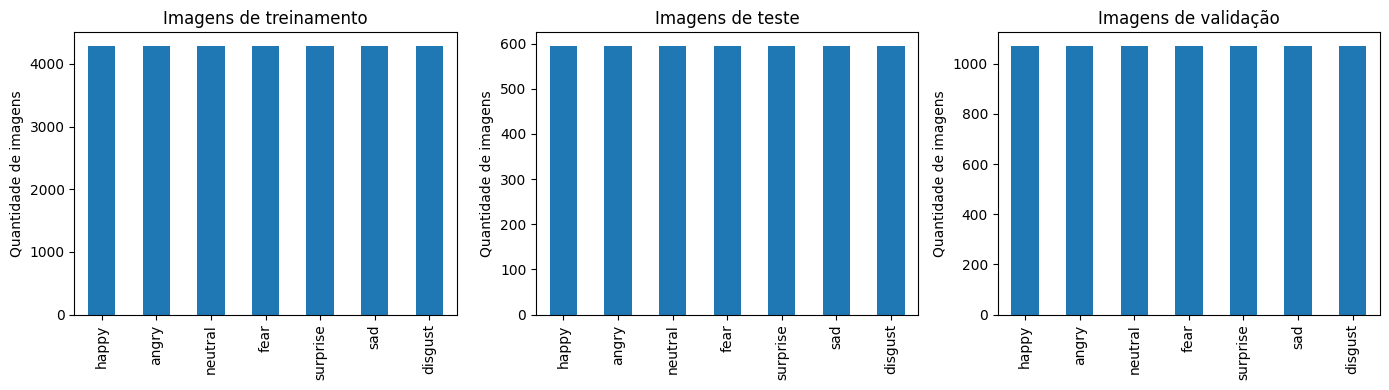

Imagens de treinamento: {'happy': 4289, 'angry': 4289, 'neutral': 4289, 'fear': 4289, 'surprise': 4289, 'sad': 4289, 'disgust': 4289}
Imagens de teste: {'happy': 595, 'angry': 595, 'neutral': 595, 'fear': 595, 'surprise': 595, 'sad': 595, 'disgust': 595}
Imagens de validação: {'happy': 1072, 'angry': 1072, 'neutral': 1072, 'fear': 1072, 'surprise': 1072, 'sad': 1072, 'disgust': 1072}


In [5]:
train_dir = '/content/RAF-DB/train/'
test_dir = '/content/RAF-DB/test/'
val_dir = '/content/RAF-DB/val/'

# Contar imagens de treinamento
train_count = {class_: len(os.listdir(os.path.join(train_dir, class_)))
               for class_ in os.listdir(train_dir)}

# Contar imagens de teste
test_count = {class_: len(os.listdir(os.path.join(test_dir, class_)))
              for class_ in os.listdir(test_dir)}

# Contar imagens de validação
val_count = {class_: len(os.listdir(os.path.join(val_dir, class_)))
              for class_ in os.listdir(val_dir)}

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
pd.Series(train_count).plot(kind="bar", ax=axes[0], title="Imagens de treinamento")
pd.Series(test_count).plot(kind="bar", ax=axes[1], title="Imagens de teste")
pd.Series(val_count).plot(kind="bar", ax=axes[2], title="Imagens de validação")
axes[0].set_ylabel("Quantidade de imagens")
axes[1].set_ylabel("Quantidade de imagens")
axes[2].set_ylabel("Quantidade de imagens")
plt.tight_layout()
plt.show()

print("Imagens de treinamento:", train_count)
print("Imagens de teste:", test_count)
print("Imagens de validação:", val_count)

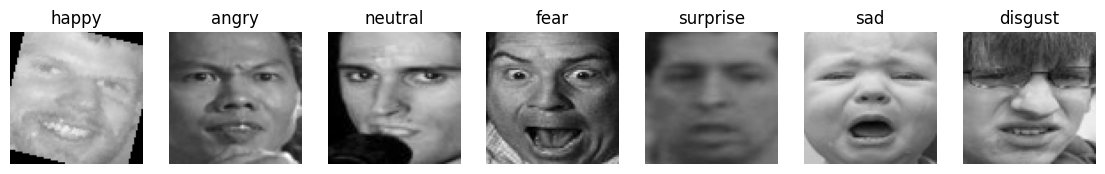

In [6]:
plt.figure(figsize=(14,4))
i = 1
for expression in os.listdir(train_dir):
    img = load_img((train_dir + expression +'/'+ os.listdir(train_dir + expression)[5]))
    plt.subplot(1,7,i)
    plt.imshow(img)
    plt.title(expression)
    plt.axis('off')
    i += 1
plt.show()

In [7]:
# Carregar os conjuntos de treino e teste
def carregar_imagens(path_dir):
    imagens = []
    rotulos = []
    mapping = {
    'angry': 0, 'disgust': 1, 'fear': 2,
    'happy': 3, 'neutral': 4, 'sad': 5, 'surprise': 6
}
    for emocao, rotulo in mapping.items():
        pasta = os.path.join(path_dir, emocao)
        for arquivo in os.listdir(pasta):
            caminho = os.path.join(pasta, arquivo)
            if os.path.isfile(caminho):
                  imagem = load_img(caminho, target_size=(75, 75), color_mode="grayscale")
                  imagens.append(img_to_array(imagem))
                  rotulos.append(rotulo)
    return np.array(imagens, dtype=np.float32) / 255.0, np.array(rotulos, dtype=np.int32)

X_train, y_train = carregar_imagens(train_dir)
X_test, y_test = carregar_imagens(test_dir)
X_val, y_val = carregar_imagens(val_dir)


print("Imagens para treinamento:", len(X_train))
print("Imagens para teste:", len(X_test))
print("Imagens para validação:", len(X_val))

Imagens para treinamento: 30023
Imagens para teste: 4165
Imagens para validação: 7504


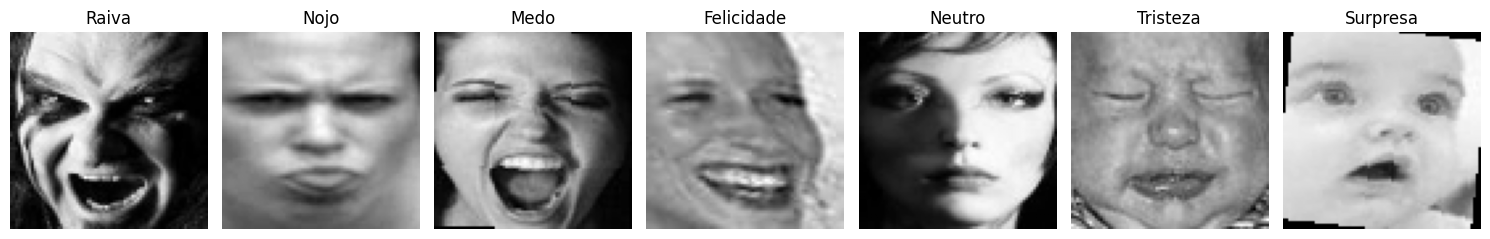

In [8]:
classes = ['Raiva', 'Nojo', 'Medo', 'Felicidade', 'Neutro', 'Tristeza', 'Surpresa']

first_image_index = {}
for i, label in enumerate(y_train):
    first_image_index.setdefault(label, i)

fig, axes = plt.subplots(1, 7, figsize=(15, 4))

for i, ax in enumerate(axes):
    ax.imshow(X_train[first_image_index[i]], cmap='gray')
    ax.set_title(classes[i])
    ax.axis('off')

plt.tight_layout()
plt.show()

In [9]:
# Modelo pré-treinado Xception
image_height = 75
image_width = 75
num_classes = 7

# Carregando modelo base Xception
base_model = tf.keras.applications.Xception(
    include_top=False,
    weights="imagenet",
    input_shape=(image_height, image_width, 3),
    pooling=None
)

base_model.trainable = True

inputs = tf.keras.Input(shape=(image_height, image_width, 1))

x = layers.Rescaling(255.0)(inputs)
# Conversão apenas de canais (1 canal para 3 canais RGB)
x = layers.Lambda(lambda img: tf.image.grayscale_to_rgb(img))(x)

# Pré-processamento padrão da Xception
x = tf.keras.applications.xception.preprocess_input(x)

x = base_model(x)
x = layers.GlobalAveragePooling2D()(x)

x = layers.Dense(256, activation="relu")(x)
x = layers.BatchNormalization()(x)
x = layers.Dropout(0.4)(x)

x = layers.Dense(128, activation="relu")(x)
x = layers.BatchNormalization()(x)
x = layers.Dropout(0.3)(x)

outputs = layers.Dense(num_classes, activation="softmax")(x)

model = tf.keras.Model(inputs, outputs, name="Xception_Complex_SingleStage")
model.summary()

Model: "Xception_Complex_SingleStage"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 75, 75, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 75, 75, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lambda (Lambda)                 │ (None, 75, 75, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 75, 75, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 75, 75, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ xception (Functional)           │ (None, 3, 3, 2048)     │    20,861,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       524,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 7)              │           903 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 21,421,359 (81.72 MB)

 Trainable params: 21,366,063 (81.51 MB)

 Non-trainable params: 55,296 (216.00 KB)

In [10]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        "best_xception_emotion.weights.h5",
        monitor="val_loss",
        mode="min",
        save_best_only=True,
        save_weights_only=True,
        verbose=1
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=10,
        restore_best_weights=True,
        verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=3,
        min_lr=1e-7,
        verbose=1
    )
]

history = model.fit(
    X_train,
    y_train,
    epochs=200,
    batch_size=64,
    validation_data=(X_val, y_val),
    callbacks=callbacks,
    verbose=1
)

Epoch 1/200
470/470 ━━━━━━━━━━━━━━━━━━━━ 0s 202ms/step - accuracy: 0.1481 - loss: 2.6999
Epoch 1: val_loss improved from None to 1.99939, saving model to best_xception_emotion.weights.h5

Epoch 1: finished saving model to best_xception_emotion.weights.h5
470/470 ━━━━━━━━━━━━━━━━━━━━ 171s 230ms/step - accuracy: 0.1619 - loss: 2.5899 - val_accuracy: 0.1939 - val_loss: 1.9994 - learning_rate: 1.0000e-05
Epoch 2/200
469/470 ━━━━━━━━━━━━━━━━━━━━ 0s 131ms/step - accuracy: 0.2045 - loss: 2.3069
Epoch 2: val_loss improved from 1.99939 to 1.82890, saving model to best_xception_emotion.weights.h5

Epoch 2: finished saving model to best_xception_emotion.weights.h5
470/470 ━━━━━━━━━━━━━━━━━━━━ 73s 155ms/step - accuracy: 0.2156 - loss: 2.2537 - val_accuracy: 0.2917 - val_loss: 1.8289 - learning_rate: 1.0000e-05
Epoch 3/200
469/470 ━━━━━━━━━━━━━━━━━━━━ 0s 131ms/step - accuracy: 0.2501 - loss: 2.0922
Epoch 3: val_loss improved from 1.82890 to 1.65982, saving model to best_xception_emotion.weights.h5


In [11]:
model.save("emotion_xception.keras")
print("Modelo Xception salvo com sucesso.")

Modelo Xception salvo com sucesso.


131/131 ━━━━━━━━━━━━━━━━━━━━ 10s 48ms/step - accuracy: 0.8591 - loss: 0.6045
Acurácia no teste: 0.8591
Perda no teste: 0.6045
66/66 ━━━━━━━━━━━━━━━━━━━━ 9s 88ms/step
              precision    recall  f1-score   support

       Raiva       0.91      0.91      0.91       595
        Nojo       0.83      0.90      0.86       595
        Medo       0.94      0.91      0.93       595
  Felicidade       0.91      0.85      0.87       595
      Neutro       0.77      0.80      0.78       595
    Tristeza       0.81      0.76      0.79       595
    Surpresa       0.86      0.89      0.87       595

    accuracy                           0.86      4165
   macro avg       0.86      0.86      0.86      4165
weighted avg       0.86      0.86      0.86      4165



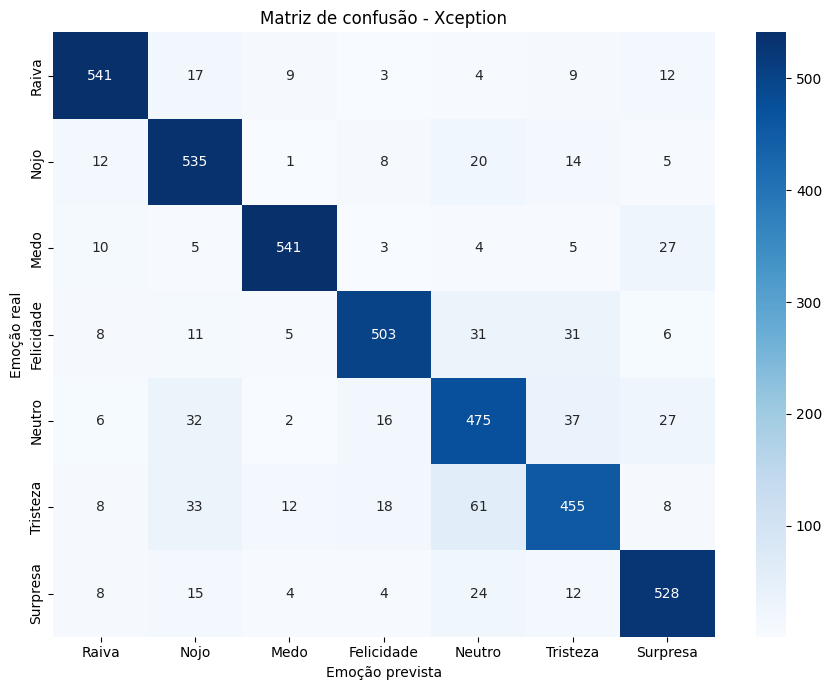

In [12]:
test_loss, test_accuracy = model.evaluate(X_test, y_test, verbose=1)
print(f"Acurácia no teste: {test_accuracy:.4f}")
print(f"Perda no teste: {test_loss:.4f}")

y_pred = np.argmax(model.predict(X_test, batch_size=64), axis=1)
nomes_classes = ["Raiva", "Nojo", "Medo", "Felicidade", "Neutro", "Tristeza", "Surpresa"]
print(classification_report(y_test, y_pred, labels=list(range(7)), target_names=nomes_classes, zero_division=0))

cm = confusion_matrix(y_test, y_pred, labels=list(range(7)))
plt.figure(figsize=(9, 7))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=nomes_classes, yticklabels=nomes_classes)
plt.xlabel("Emoção prevista")
plt.ylabel("Emoção real")
plt.title("Matriz de confusão - Xception")
plt.tight_layout()
plt.show()

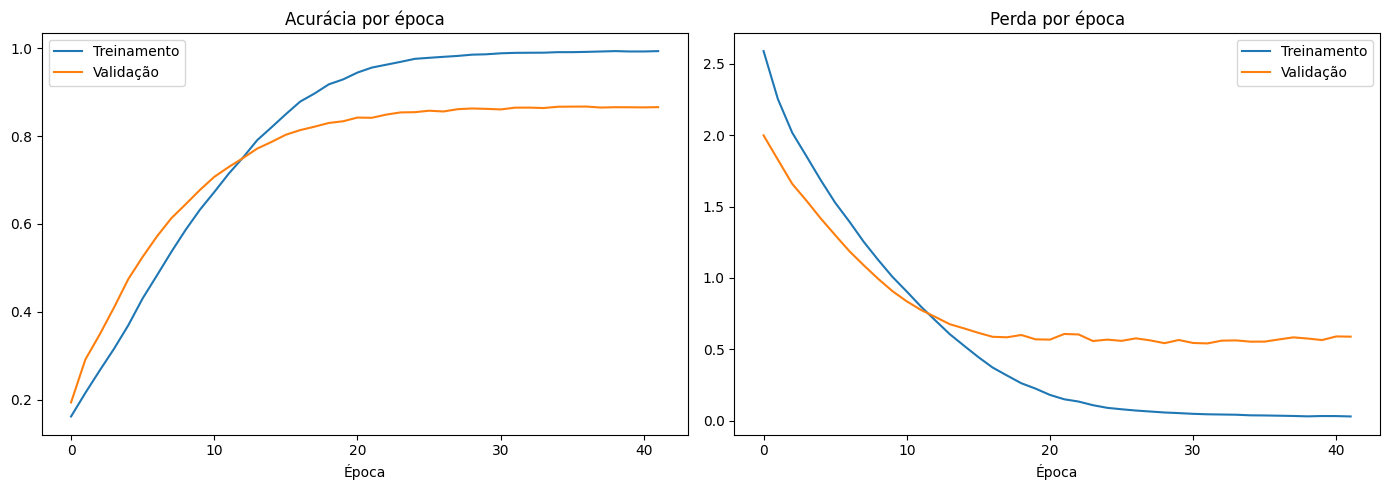

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(history.history["accuracy"], label="Treinamento")
axes[0].plot(history.history["val_accuracy"], label="Validação")
axes[0].set_title("Acurácia por época")
axes[0].set_xlabel("Época")
axes[0].legend()
axes[1].plot(history.history["loss"], label="Treinamento")
axes[1].plot(history.history["val_loss"], label="Validação")
axes[1].set_title("Perda por época")
axes[1].set_xlabel("Época")
axes[1].legend()
plt.tight_layout()
plt.show()

In [14]:
resultados = model.evaluate(X_test, y_test, verbose=0)
for nome, valor in zip(model.metrics_names, resultados):
    print(f"{nome}: {valor:.4f}")

loss: 0.6045
compile_metrics: 0.8591


In [15]:
np.random.seed(42)

indices = np.random.choice(
    len(X_train),
    size=min(30, len(X_train)),
    replace=False
)

background = X_train[indices]

# Selecionar poucas imagens para explicar
X_explain = X_test[:5]

# Criar o explicador SHAP
explainer = shap.GradientExplainer(model, background)

# Calcular os valores SHAP
shap_values = explainer.shap_values(X_explain)

print("Formato das imagens:", X_explain.shape)
print("Explicações SHAP calculadas.")

/usr/local/lib/python3.13/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: keras_tensor_132
Received: inputs=['Tensor(shape=(5, 75, 75, 1))']
  warnings.warn(msg)
/usr/local/lib/python3.13/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: keras_tensor_132
Received: inputs=['Tensor(shape=(50, 75, 75, 1))']
  warnings.warn(msg)


Formato das imagens: (5, 75, 75, 1)
Explicações SHAP calculadas.


/usr/local/lib/python3.13/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: keras_tensor_132
Received: inputs=['Tensor(shape=(7, 75, 75, 1))']
  warnings.warn(msg)


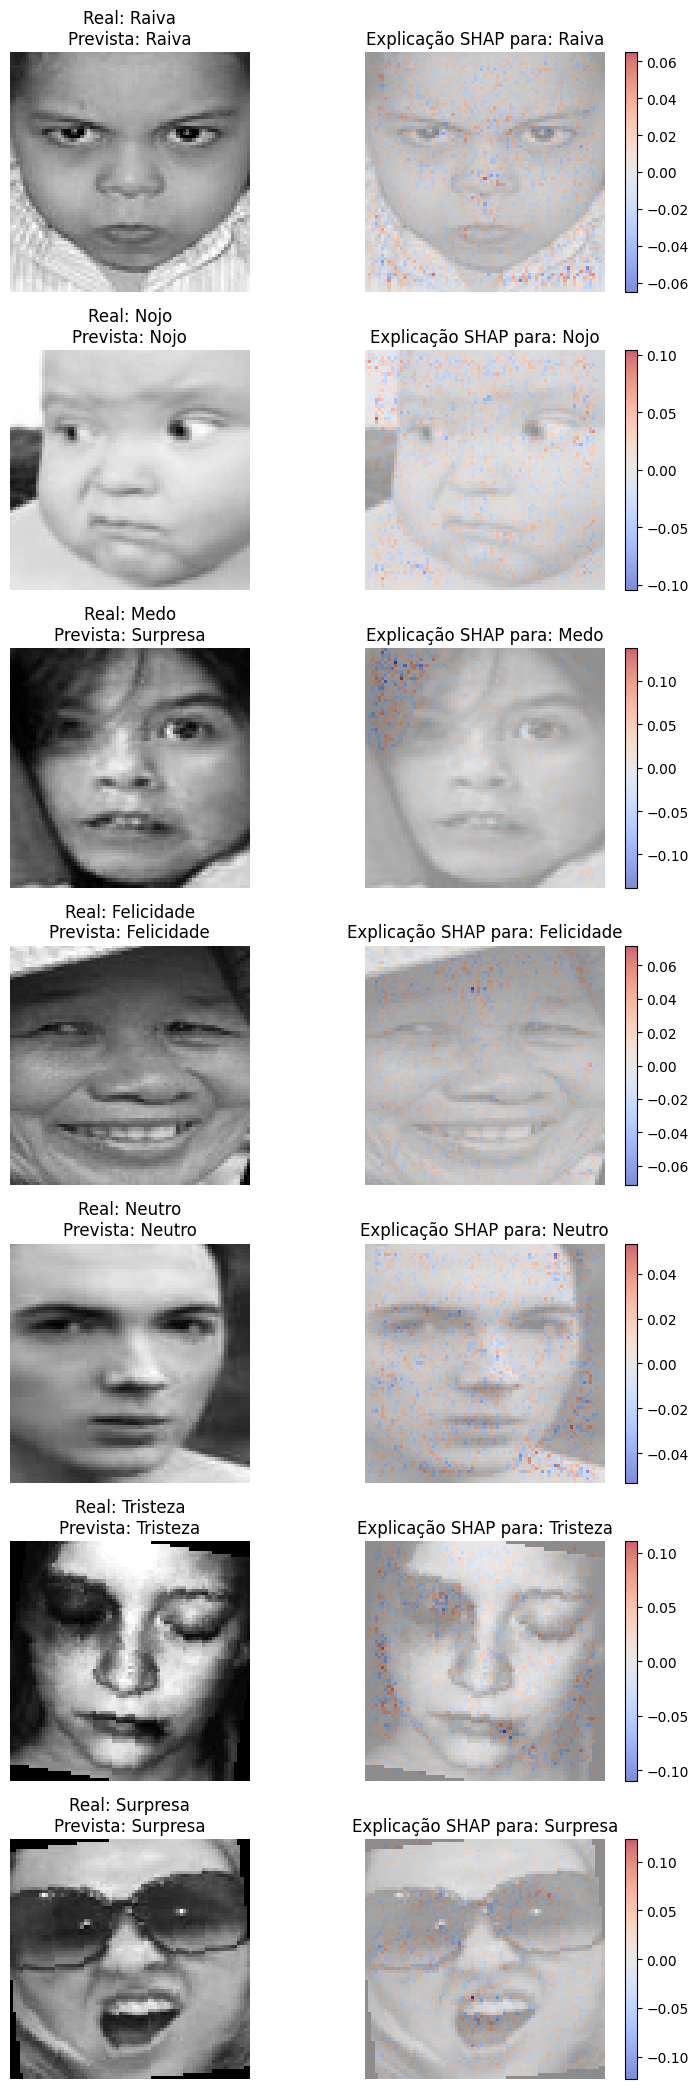

In [16]:
# Encontrar o primeiro índice no conjunto de teste para cada uma das 7 classes
indices_por_classe = {}
for idx, label in enumerate(y_test):
    if label not in indices_por_classe and len(indices_por_classe) < 7:
        indices_por_classe[label] = idx

indices_selecionados = [indices_por_classe[i] for i in range(7)]

# Extrair as 7 imagens de exemplo (uma de cada emoção)
X_explain_7 = X_test[indices_selecionados]
y_explain_7 = y_test[indices_selecionados]

# Calcular os valores SHAP para essas 7 imagens usando o explicador já existente
shap_values_7 = explainer.shap_values(X_explain_7)

# Ajustar formato do SHAP caso necessário
if isinstance(shap_values_7, list):
    valores_por_classe_7 = shap_values_7
else:
    shap_values_7 = np.asarray(shap_values_7)
    if shap_values_7.ndim == 5:
        valores_por_classe_7 = [
            shap_values_7[..., i]
            for i in range(shap_values_7.shape[-1])
        ]

# Obter as predições do modelo para estas imagens
predicoes_7 = np.argmax(model.predict(X_explain_7, verbose=0), axis=1)

fig, axes = plt.subplots(7, 2, figsize=(8, 3 * 7))
for i in range(7):
    classe_real = y_explain_7[i]
    classe_prevista = predicoes_7[i]

    imagem = X_explain_7[i].squeeze()
    explicacao = valores_por_classe_7[classe_real][i].sum(axis=-1)

    limite = np.max(np.abs(explicacao)) + 1e-8

    # Imagem Original
    axes[i, 0].imshow(imagem, cmap="gray")
    axes[i, 0].set_title(f"Real: {nomes_classes[classe_real]}\nPrevista: {nomes_classes[classe_prevista]}")

    # Mapa de Calor SHAP
    axes[i, 1].imshow(imagem, cmap="gray")
    mapa = axes[i, 1].imshow(
        explicacao,
        cmap="coolwarm",
        alpha=0.65,
        vmin=-limite,
        vmax=limite
    )
    axes[i, 1].set_title(f"Explicação SHAP para: {nomes_classes[classe_real]}")
    fig.colorbar(mapa, ax=axes[i, 1], fraction=0.046)

    for ax in axes[i]:
        ax.axis("off")

plt.tight_layout()
plt.show()